# Scale: rewards ×1000 and badly scaled observations

**Code:** [`algos/popart_dqn.py`](../algos/popart_dqn.py) · [`experiments/reward_normalisation.py`](../experiments/reward_normalisation.py) · [`experiments/obs_normalisation.py`](../experiments/obs_normalisation.py) · [`envs/pointmass.py`](../envs/pointmass.py)
**Papers:** Ioffe & Szegedy 2015, BatchNorm ([PDF](../papers/normalisation/ioffe-szegedy-2015-batchnorm.pdf)), van Hasselt et al. 2016, PopArt ([PDF](../papers/normalisation/vanhasselt-2016-popart.pdf)) ·
**Notes:** [`papers/normalisation/notes.md`](../papers/normalisation/notes.md)

Normalisation changes nothing about the mathematics of a problem and a great deal about whether it can be learned.

1. **Rewards ×1000 on CartPole.** The optimal policy is unchanged. DQN as-is, clipped rewards, the known scale divided out, and PopArt.
2. **PopArt preserves outputs:** its statistics can move without changing a single Q value.
3. **Observations on very different scales** (PointMass): TD3 with raw inputs against a running mean/std normaliser.

Section 2 runs live; sections 1 and 3 read `experiments/results/normalisation/` (`python experiments/reward_normalisation.py`, `python experiments/obs_normalisation.py`).

In [1]:
import json, pathlib
import numpy as np
import matplotlib.pyplot as plt
import torch

from algos.popart_dqn import PopArtQ
from envs.pointmass import PointMass

torch.set_num_threads(1)
plt.rcParams["figure.dpi"] = 110
ROOT = pathlib.Path("..") if pathlib.Path("../algos").exists() else pathlib.Path(".")
RESULTS = ROOT / "experiments/results/normalisation"
load = lambda prefix: [json.loads(p.read_text()) for p in sorted(RESULTS.glob(f"{prefix}*.json"))]

## 0. The two problems

**CartPole-v1**: +1 per step balanced, at most 500. In section 1 every reward is multiplied by 1,000 during training; the return is always reported in the original units.

**PointMass**: push a point mass to the origin and stop there. Observation $[x, y, v_x, v_y]$, action a force in $[-1, 1]^2$, reward −distance per step, 200 steps.
Position stays within ±1; velocity does not. The printed spread below is why it is a normalisation test.

column      min      max      std   (20 random-action episodes)
     x    -1.00     1.00     0.68
     y    -1.00     1.00     0.66
   v_x   -11.43    12.10     3.64
   v_y   -12.26    10.06     3.18


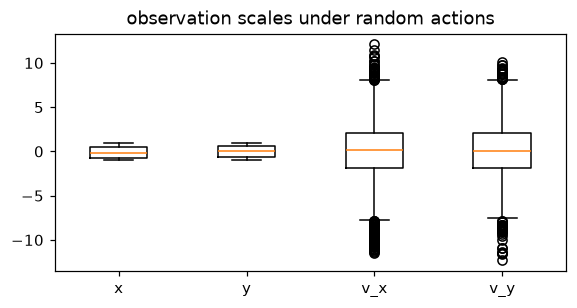

In [2]:
env = PointMass()
rng = np.random.default_rng(0)
obs_log = []
for episode in range(20):
    obs, _ = env.reset(seed=episode)
    done = False
    while not done:
        obs, reward, terminated, truncated, _ = env.step(rng.uniform(-1, 1, 2))
        obs_log.append(obs); done = terminated or truncated
obs_log = np.array(obs_log)
print(f"{'column':>6} {'min':>8} {'max':>8} {'std':>8}   (20 random-action episodes)")
for i, name in enumerate(["x", "y", "v_x", "v_y"]):
    print(f"{name:>6} {obs_log[:, i].min():>8.2f} {obs_log[:, i].max():>8.2f} {obs_log[:, i].std():>8.2f}")
plt.figure(figsize=(6, 2.8)); plt.boxplot([obs_log[:, i] for i in range(4)], tick_labels=["x", "y", "v_x", "v_y"])
plt.title("observation scales under random actions"); plt.show()

## 1. Rewards ×1000

DQN, 100,000 steps, 3 seeds. Configurations ([`experiments/reward_normalisation.py`](../experiments/reward_normalisation.py)):

| config | what the learner sees |
| --- | --- |
| scale 1 | the original reward, the reference |
| scale 1000 | reward ×1000, nothing done |
| scale 1000, clipped | clipped to [−1, 1], as the 2015 DQN did on Atari |
| scale 1000, /1000 | divided by the known scale: the oracle fix |
| scale 1000, PopArt | adaptive normalisation of the targets ([`popart_dqn.py`](../algos/popart_dqn.py)) |

                        final greedy, median [min, max]  mean over curve  peak |mean Q|
               scale 1             500.0 [110.2, 500.0]            253.7           97.8
            scale 1000               9.2 [  9.2,   9.5]              9.2     87144184.0
   scale 1000, clipped             500.0 [110.2, 500.0]            253.7           97.8
     scale 1000, /1000             500.0 [110.2, 500.0]            253.7           97.8
    scale 1000, PopArt             113.6 [106.3, 453.6]            248.9       111546.4


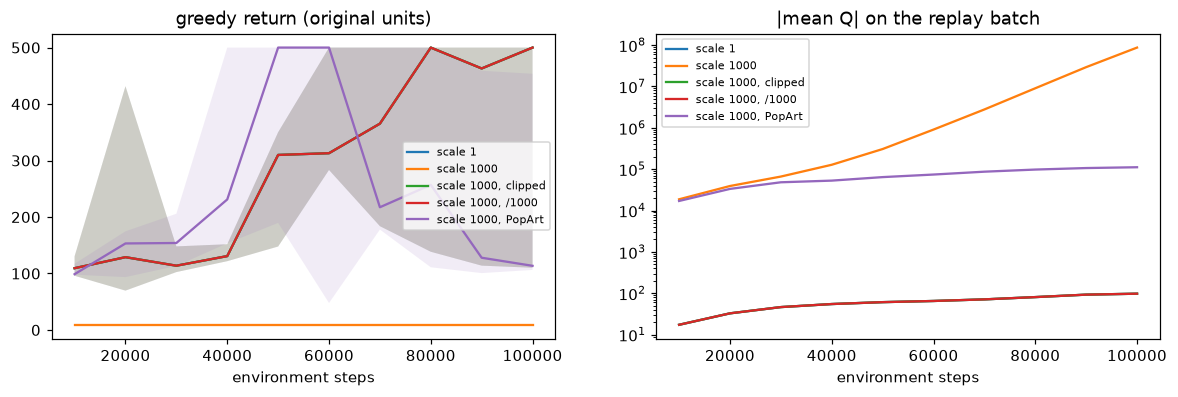

In [3]:
rows = load("reward__")
order = ["scale 1", "scale 1000", "scale 1000, clipped", "scale 1000, /1000", "scale 1000, PopArt"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
print(f"{'':>22} {'final greedy, median [min, max]':>32} {'mean over curve':>16} {'peak |mean Q|':>14}")
for name in order:
    runs = [r for r in rows if r["name"] == name]
    final = np.array([r["log"][-1]["score"] for r in runs])
    area = np.median([np.mean([e["score"] for e in r["log"]]) for r in runs])
    peak = np.median([max(abs(e["q"]) for e in r["log"]) for r in runs])
    print(f"{name:>22} {f'{np.median(final):6.1f} [{final.min():5.1f}, {final.max():5.1f}]':>32} {area:>16.1f} {peak:>14.1f}")
    steps = [e["step"] for e in runs[0]["log"]]
    scores = np.array([[e["score"] for e in r["log"]] for r in runs])
    axs[0].plot(steps, np.median(scores, 0), label=name); axs[0].fill_between(steps, scores.min(0), scores.max(0), alpha=0.12)
    axs[1].plot(steps, np.median([[abs(e["q"]) for e in r["log"]] for r in runs], 0), label=name)
axs[0].set_title("greedy return (original units)"); axs[1].set_title("|mean Q| on the replay batch"); axs[1].set_yscale("log")
for ax in axs: ax.set_xlabel("environment steps"); ax.legend(fontsize=7)
plt.show()

- **×1000, nothing done:** DQN diverges, its mean Q reaching about 10⁸, and never learns: 9.2 steps, a policy that pushes the same way every step (a random policy lasts about 20).
- **Clipped** and **divided by 1,000** are identical to the reference on every seed. That is arithmetic, not luck: every CartPole reward is +1, so both map the scaled reward back to exactly the original. This task cannot show clipping's real cost, which needs rewards of different sizes.
- **PopArt**, told nothing about the scale, recovers the reference learning curve (mean over the curve 248.9 against 253.7), with Q at its true magnitude of about 10⁵. It reaches 500 sooner than the reference (median 500 at 50,000-60,000 steps) and then falls back; its final returns vary more (106.3 to 453.6).

## 2. PopArt preserves outputs

The network predicts a normalised value $f$; $Q = \sigma f + \mu$. When the running statistics change, PopArt rescales the last layer,
$W \leftarrow W\sigma_{old}/\sigma_{new}$, $b \leftarrow (\sigma_{old} b + \mu_{old} - \mu_{new})/\sigma_{new}$, so that $Q$ is unchanged.
Below: a large jump in the statistics, then the largest change in any Q value.

In [4]:
torch.manual_seed(0)
net = PopArtQ(4, 2); x = torch.randn(256, 4)
before = net(x).detach().clone()
print(f"{'update':>6} {'mu':>9} {'sigma':>9} {'max |ΔQ|':>11}")
for i in range(5):
    net.update_stats(torch.randn(64) * 500 + 1000 * (i + 1), rate=0.5)
    print(f"{i + 1:>6} {float(net.mu):>9.1f} {float(net.sigma):>9.1f} {float((net(x) - before).abs().max()):>11.2e}")
print("\nWithout the rescaling (ART without POP), the same updates would move every Q by roughly the change in mu.")

update        mu     sigma    max |ΔQ|
     1     529.3     615.5    3.58e-04
     2    1275.1     936.6    8.61e-04
     3    2076.6    1110.9    8.95e-04
     4    3085.6    1314.9    2.18e-03
     5    4007.1    1348.2    2.66e-03

Without the rescaling (ART without POP), the same updates would move every Q by roughly the change in mu.


/var/folders/gf/py2bkq010_gd3k4m93w4_dgm0000gn/T/ipykernel_1691/773263653.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print(f"{i + 1:>6} {float(net.mu):>9.1f} {float(net.sigma):>9.1f} {float((net(x) - before).abs().max()):>11.2e}")


## 3. Badly scaled observations

TD3 on PointMass, 30,000 steps, 3 seeds, raw observations against observations passed through a running mean/std normaliser (updated during training, frozen during evaluation).
The reference is the hand-written PD controller in `PointMass.expert_action`.

PD controller return: -13.34

       raw: final return per seed [-7.57, -5.41, -5.95]
normalised: final return per seed [-71.85, -17.58, -5.11]


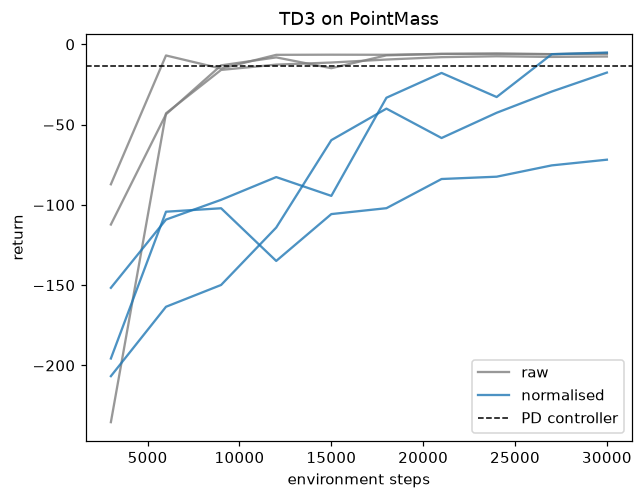

In [5]:
obs_rows = load("obs__")
expert = obs_rows[0]["expert"]
print(f"PD controller return: {expert:.2f}\n")
for normalise, label in ((False, "raw"), (True, "normalised")):
    runs = [r for r in obs_rows if r["normalise"] == normalise]
    final = [round(r["log"][-1]["score"], 2) for r in runs]
    print(f"{label:>10}: final return per seed {final}")
    for r in runs:
        plt.plot([e["step"] for e in r["log"]], [e["score"] for e in r["log"]], color="tab:blue" if normalise else "tab:grey",
                 alpha=0.8, label=label if r is runs[0] else None)
plt.axhline(expert, color="k", ls="--", lw=1, label="PD controller")
plt.xlabel("environment steps"); plt.ylabel("return"); plt.legend(); plt.title("TD3 on PointMass"); plt.show()

The result goes against expectation, and against the claim in `envs/pointmass.py`. **Raw** observations learn faster here: every raw seed reaches about −15 within 6,000 steps and ends between −7.6 and −5.4, better than the PD controller.
The normalised runs are slower on every seed and end at −71.9, −17.6 and −5.1.

HYPOTHESIS (unverified): the normaliser is applied when observations are stored, so replay entries from early training sit on a different scale from later ones while the statistics are still moving.
Storing raw observations and normalising when a batch is sampled would test it. As measured, a running normaliser is not a free fix for an off-policy agent.

## 4. What breaks, and how you would know

| symptom | likely cause |
| --- | --- |
| learning is slow or stalls after a reward rescale that "changes nothing" | value scale vs learning rate; normalise targets (PopArt) or rewards |
| clipped rewards learn a different policy | clipping erases magnitude; fine on CartPole (all +1), wrong where rewards differ in size |
| PopArt collapses whenever the statistics move | the last layer is not rescaled: ART without POP |
| a correct agent does nothing on a new environment | observation scales differ by orders of magnitude; normalise inputs |
| evaluation differs from training with a normaliser | the statistics kept updating during evaluation, or were not saved with the model |